# 1.0 Exploración de datos de MiBici

Exploración inicial de viajes (2025-01 a 2026-09) y estaciones. La lógica final vive en el módulo `mibici`; este notebook solo explora y justifica las decisiones de `features.py`.

Requiere haber corrido `make data`.

In [1]:
# Librerías y datos limpios versionados
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mibici import features as F
from mibici.config import FIGURES_DIR, P2_HORAS_BLOQUE, TRAIN_FIN, VAL_FIN
from mibici.dataset import cargar_estaciones, cargar_manifiesto, cargar_viajes

EDA_DIR = FIGURES_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
manifiesto = cargar_manifiesto()
viajes = cargar_viajes()
estaciones = cargar_estaciones()
print("Versión de datos:", manifiesto["version"])
print(manifiesto["totales"])

Versión de datos: v1-fc921063bb48
{'meses': 21, 'viajes_crudos': 7894097, 'viajes_limpios': 7666077, 'estaciones_nomenclatura': 484}


## 1. Tamaño y calidad

In [2]:
# Registros crudos, limpios y descartados por mes
meses = pd.DataFrame(manifiesto["archivos"]).set_index("mes")
desc = pd.DataFrame(list(meses["descartes"]), index=meses.index)
resumen = pd.concat([meses[["encoding", "filas_crudas", "filas_limpias"]], desc], axis=1)
resumen

,encoding,filas_crudas,filas_limpias,nulos_o_formato,duplicados,duracion_no_positiva,duracion_mayor_max,devolucion_inmediata
mes,,,,,,,,
2025-01,latin-1,380184,371220,0,0,205,10,8749
2025-02,latin-1,372529,363830,0,0,194,15,8490
2025-03,utf-8,405110,395168,0,0,216,20,9706
2025-04,utf-8,366193,357327,0,0,185,11,8670
2025-05,utf-8,395891,386198,0,0,189,11,9493
2025-06,utf-8,356611,347380,0,0,278,24,8929
2025-07,latin-1,368186,358737,0,0,253,12,9184
2025-08,utf-8,374727,364976,0,0,275,20,9456
2025-09,utf-8,376789,367004,0,0,228,14,9543


In [3]:
# Porcentaje descartado en todo el periodo
print(f"Descartado: {1 - resumen.filas_limpias.sum() / resumen.filas_crudas.sum():.2%}")
viajes.describe(include="all").T

Descartado: 2.89%


,count,mean,min,25%,50%,75%,max,std
viaje_id,7666077.0,41685173.257216,37162342.0,39408926.0,41666939.0,43927746.0,46255558.0,2625539.837572
inicio,7666077,2025-11-16 03:33:34.896000,2025-01-01 00:00:44,2025-06-04 14:07:39,2025-11-10 08:50:52,2026-04-27 15:28:10,2026-09-30 23:59:48,NaN
fin,7666077,2025-11-16 03:44:54.380000,2025-01-01 00:11:29,2025-06-04 14:18:12,2025-11-10 09:01:37,2026-04-27 15:39:17,2026-10-01 00:14:52,NaN
origen_id,7666077.0,159.862808,2.0,51.0,157.0,260.0,519.0,117.845936
destino_id,7666077.0,161.746143,2.0,51.0,157.0,266.0,519.0,120.599367
duracion_s,7666077.0,679.484116,2.0,362.0,582.0,901.0,21577.0,454.906814


## 2. Demanda en el tiempo y partición temporal

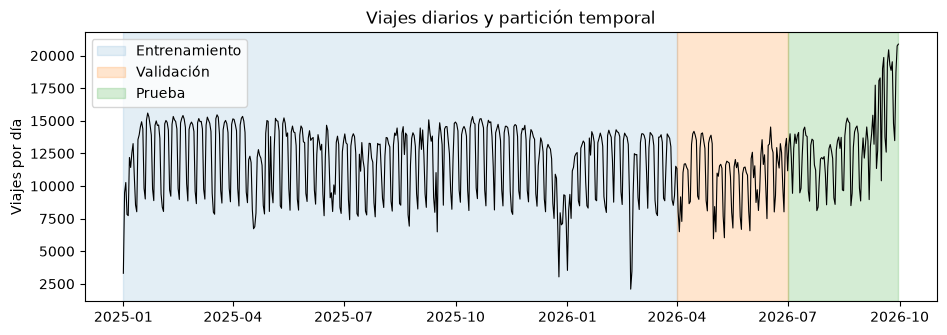

In [4]:
# Viajes por día con los periodos de entrenamiento, validación y prueba
diario = viajes.set_index("inicio").resample("D").size()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(diario.index, diario.values, lw=0.8, color="black")
ax.axvspan(diario.index.min(), pd.Timestamp(TRAIN_FIN), alpha=0.12, color="tab:blue", label="Entrenamiento")
ax.axvspan(pd.Timestamp(TRAIN_FIN), pd.Timestamp(VAL_FIN), alpha=0.2, color="tab:orange", label="Validación")
ax.axvspan(pd.Timestamp(VAL_FIN), diario.index.max(), alpha=0.2, color="tab:green", label="Prueba")
ax.set_ylabel("Viajes por día")
ax.set_title("Viajes diarios y partición temporal")
ax.legend(loc="upper left")
fig.savefig(EDA_DIR / "viajes_diarios_particion.png", dpi=130, bbox_inches="tight")

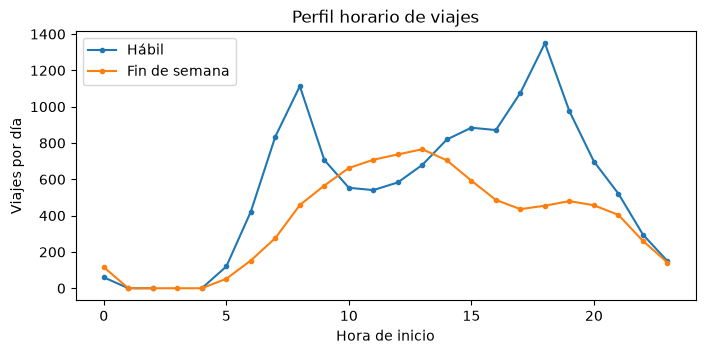

In [5]:
# Perfil por hora: días hábiles frente a fin de semana
v = viajes.assign(hora=viajes.inicio.dt.hour, finde=viajes.inicio.dt.dayofweek >= 5)
dias = v.groupby("finde").inicio.agg(lambda s: s.dt.normalize().nunique())
perfil = v.groupby(["finde", "hora"]).size().unstack(0) / dias
perfil.columns = ["Hábil", "Fin de semana"]
ax = perfil.plot(figsize=(8, 3.5), marker="o", ms=3)
ax.set_xlabel("Hora de inicio")
ax.set_ylabel("Viajes por día")
ax.set_title("Perfil horario de viajes")
plt.savefig(EDA_DIR / "perfil_horario.png", dpi=130, bbox_inches="tight")

count    7.666077e+06
mean     1.132474e+01
std      7.581780e+00
min      3.333333e-02
50%      9.700000e+00
90%      2.083333e+01
99%      3.336667e+01
max      3.596167e+02
Name: duracion_s, dtype: float64

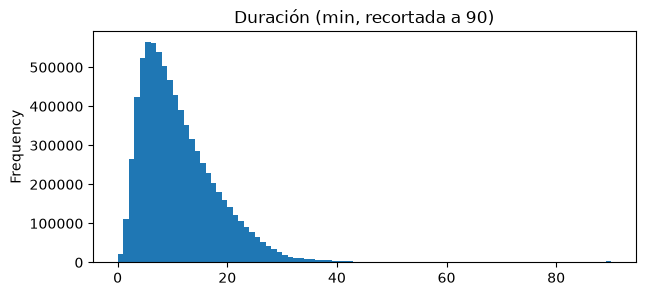

In [6]:
# Duración de los viajes en minutos
(viajes.duracion_s / 60).clip(upper=90).plot.hist(bins=90, figsize=(7, 3), title="Duración (min, recortada a 90)")
(viajes.duracion_s / 60).describe(percentiles=[0.5, 0.9, 0.99])

## 3. Estaciones

In [7]:
# Estaciones activas, retiradas y concentración de la demanda
salidas = viajes.origen_id.value_counts()
print("Estaciones en nomenclatura:", len(estaciones), "| retiradas:", estaciones.retirada.sum())
print("Estaciones con viajes:", salidas.size)
print("Viajes de estaciones fuera de la nomenclatura:", (~viajes.origen_id.isin(estaciones.estacion_id)).sum())
print(f"El 20% de estaciones con más salidas concentra {salidas.head(len(salidas) // 5).sum() / salidas.sum():.1%} de los viajes")
estaciones.groupby("municipio").agg(estaciones=("estacion_id", "size"), capacidad_media=("capacidad", "mean"))

Estaciones en nomenclatura: 484 | retiradas: 14
Estaciones con viajes: 472
Viajes de estaciones fuera de la nomenclatura: 1894
El 20% de estaciones con más salidas concentra 54.8% de los viajes


,estaciones,capacidad_media
municipio,,
GDL,357,17.182073
TLQ,17,15.235294
ZPN,110,16.163636


## 4. Base para P1 y P2: conteos por estación y hora

In [8]:
# Malla estación-hora con ceros
conteos = F.conteos_por_hora(viajes, estaciones)
print(conteos.shape)
print(f"Horas sin salidas: {(conteos.salidas == 0).mean():.1%}")
conteos.salidas.describe()

(5875598, 4)
Horas sin salidas: 54.3%


count    5.875598e+06
mean     1.304409e+00
std      2.436697e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      2.000000e+00
max      2.050000e+02
Name: salidas, dtype: float64

In [9]:
# Autocorrelación de salidas: justifica los rezagos de 24 h y 168 h
s = conteos[conteos.estacion_id == salidas.index[0]].set_index("hora").salidas
pd.Series({k: s.autocorr(k) for k in [1, 24, 48, 72, 168, 336]}, name="autocorrelación")

1      0.668130
24     0.683366
48     0.585482
72     0.567479
168    0.776699
336    0.766031
Name: autocorrelación, dtype: float64

## 5. Aproximación del riesgo para P2

In [10]:
# Flujo neto por bloque relativo a la capacidad
bloques = F.conteos_por_bloque(conteos).merge(estaciones[["estacion_id", "capacidad"]], on="estacion_id")
bloques = bloques[bloques.capacidad > 0]
rel = bloques.flujo_neto / bloques.capacidad
print(rel.describe(percentiles=[0.01, 0.05, 0.95, 0.99]))
umbrales = [0.3, 0.4, 0.5, 0.6, 0.75]
pd.Series({u: (rel.abs() >= u).mean() for u in umbrales}, name="tasa de riesgo")

count    1958663.0
mean     -0.002261
std       0.199008
min      -6.789474
1%       -0.545455
5%       -0.272727
95%       0.272727
99%       0.565217
max       4.025641
dtype: Float64


0.30    0.094142
0.40    0.055587
0.50    0.028384
0.60    0.017673
0.75    0.006589
Name: tasa de riesgo, dtype: float64

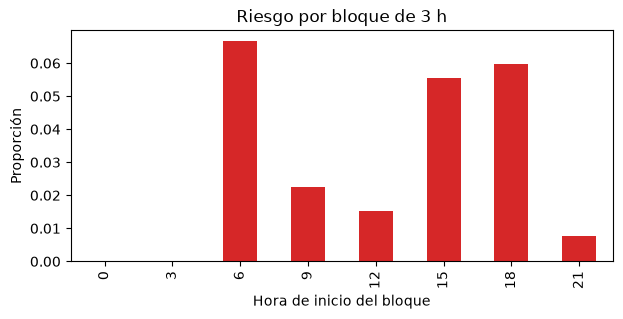

In [11]:
# Tasa de riesgo por bloque horario con el umbral elegido (0.5 x capacidad)
riesgo = rel.abs() >= 0.5
tasa = riesgo.groupby(bloques.bloque.dt.hour).mean()
ax = tasa.plot.bar(figsize=(7, 3), color="tab:red", title=f"Riesgo por bloque de {P2_HORAS_BLOQUE} h")
ax.set_xlabel("Hora de inicio del bloque")
ax.set_ylabel("Proporción")
plt.savefig(EDA_DIR / "riesgo_por_bloque.png", dpi=130, bbox_inches="tight")

## Conclusiones

- Los archivos alternan entre UTF-8 y Latin-1 y cambian comillas y nombre de columnas; la ingesta lo normaliza (también acepta el formato `DD/MM/AAAA H:MM` que usan meses anteriores, como octubre de 2024).
- La demanda tiene ciclo diario (picos 7-9 h y 17-19 h) y semanal: se usan rezagos de 24 h y 168 h y el promedio de la misma hora en 4 semanas.
- Más de la mitad de las horas estación tienen cero salidas: conviene pérdida Poisson y métricas absolutas (MAE, WAPE) en P1.
- Con un umbral de 0.5 x capacidad, cerca del 3% de los bloques están en riesgo, sobre todo en las horas pico: P2 es desbalanceado y se evalúa con PR-AUC.
- 101 estaciones empiezan a operar entre abril y septiembre de 2026; la malla de cada estación inicia en su primera actividad.